<a href="https://colab.research.google.com/github/Penguinboy1990/Machine-Learning/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dimensionality Reduction, Reconstruction, and Non-Linear Classification on Face Images

Imports

In [1]:
from sklearn.datasets import fetch_olivetti_faces
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, mean_squared_error)

1) Dataset Loading and Dimensionality Inspection

Load the Olivetti Faces dataset using sklearn.datasets.fetch_olivetti_faces. Print the total number of samples, unique target subjects, feature dimensions, and plot a 4 x 5 grid of sample faces labeled with their subject IDs.

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Total number of samples: 400
Number of unique target subjects: 40
Feature dimensions: 4096
Image dimensions: (64, 64)


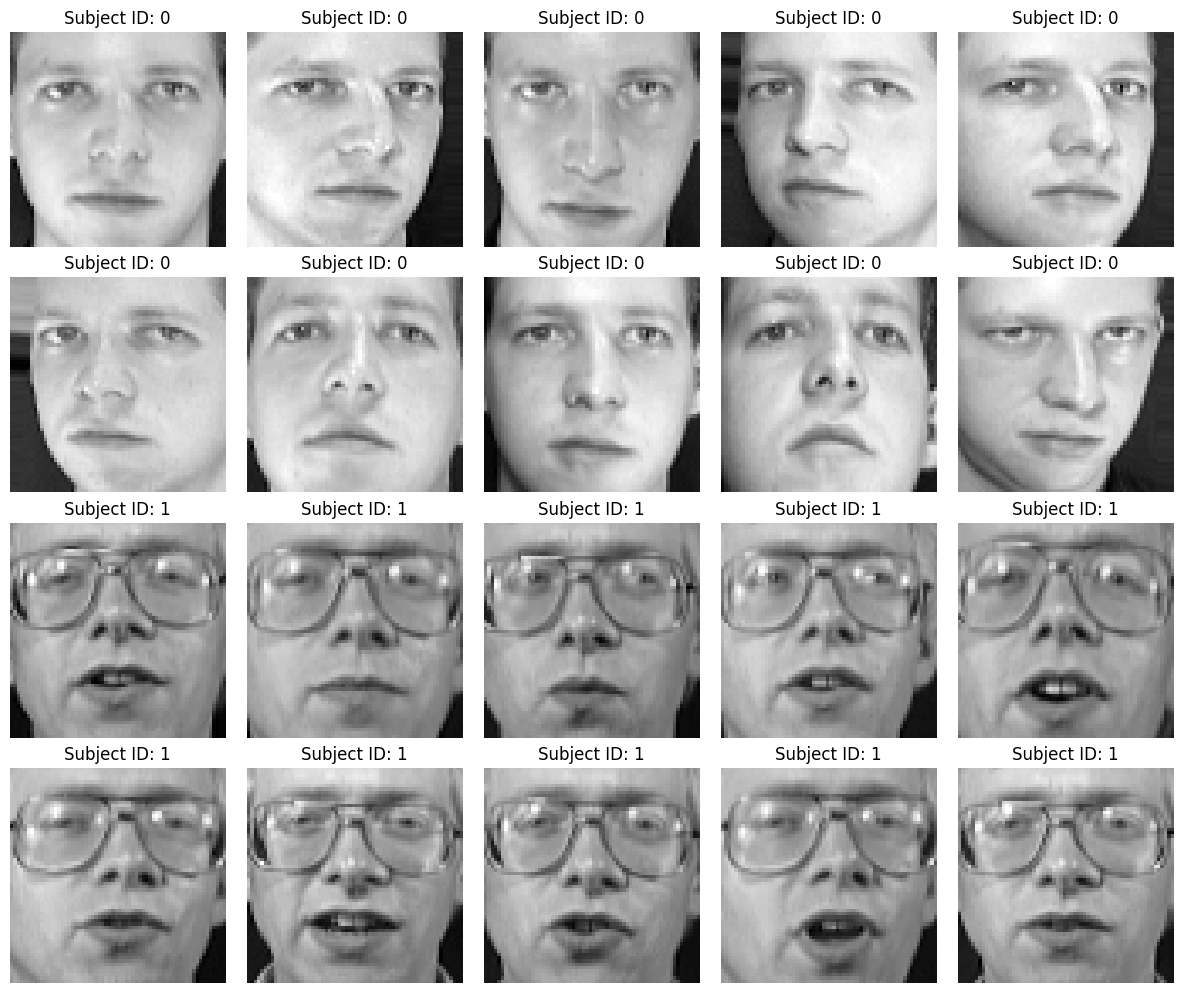

In [2]:
faces = fetch_olivetti_faces() # Loads the dataset

X = faces.data # Extracts variables
y = faces.target # Extracts target label
images = faces.images # Extracts images

# Prints the dataset information
print("Total number of samples:", X.shape[0])
print("Number of unique target subjects:", len(set(y)))
print("Feature dimensions:", X.shape[1])
print("Image dimensions:", images.shape[1:])

fig, axes = plt.subplots(4, 5, figsize=(12, 10)) # Plots a 4x5 grid of sample faces

for i, ax in enumerate(axes.flat):
  ax.imshow(images[i], cmap="gray")
  ax.set_title(f"Subject ID: {y[i]}")
  ax.axis("off")

plt.tight_layout()
plt.show()

2) Cumulative Explained Variance & Elbow

Plot Fit a full PCA model on the dataset. Plot both the individual explained variance ratio and the cumulative explained variance curve versus the number of principal components. Determine and print the exact number of components required to preserve 90%, 95%, and 99% of the cumulative variance.

Number of PCA components: 400
90.0 % variance
66  components
cumulative variance =  0.9002 %
95.0 % variance
123  components
cumulative variance =  0.9504 %
99.0 % variance
260  components
cumulative variance =  0.99 %


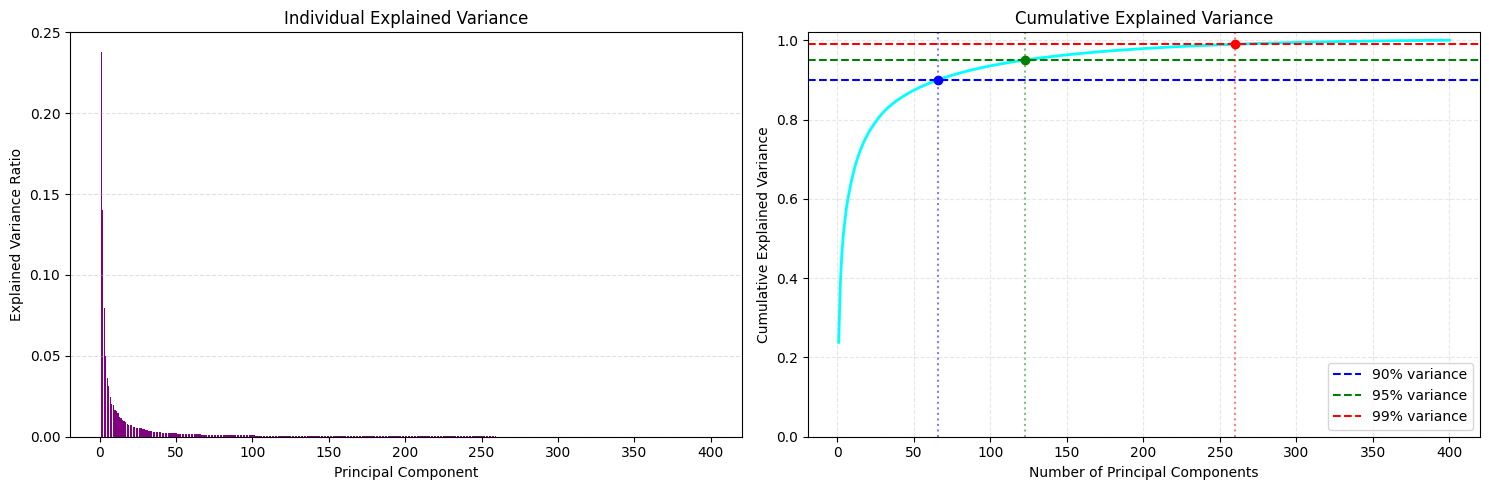

In [18]:
# Fits PCA using all available components
pca = PCA()
pca.fit(X)

# Calculates individual and cumulative explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)
components = np.arange(1, len(explained_variance) + 1)
print("Number of PCA components:", pca.n_components_)

for threshold in [0.90, 0.95, 0.99]:
  n_components = np.argmax(cumulative_variance >= threshold) + 1
  actual_variance = cumulative_variance[n_components - 1]

  print(np.round(threshold * 100), "% variance")
  print(np.round(n_components,0)," components")
  print("cumulative variance = ", np.round(actual_variance,4), "%")

# Plots individual and cumulative explained variance
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Individual explained variance
axes[0].bar(components, explained_variance, color="purple")
axes[0].set_title("Individual Explained Variance")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

# Cumulative explained variance
axes[1].plot(components, cumulative_variance, color="cyan", linewidth=2)

colors = ["blue", "green", "red"]

for threshold, color in zip([0.90, 0.95, 0.99], colors):
  n = np.argmax(cumulative_variance >= threshold) + 1
  axes[1].axhline(y=threshold, color=color, linestyle="--", label=f"{threshold:.0%} variance")
  axes[1].axvline(x=n, color=color, linestyle=":", alpha=0.5)
  axes[1].scatter(n, cumulative_variance[n - 1], color=color, zorder=3)

axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Principal Components")
axes[1].set_ylabel("Cumulative Explained Variance")
axes[1].set_ylim(0, 1.02)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

3) Image Compression and Reconstruction Analysis

Select 5 representative facial images. Compress and reconstruct them using PCA with varying numbers of components; e.g., k in {10, 50, 100, 200, 300}. Plot a grid comparing the original images against their reconstructions across each component threshold, and compute/plot the Mean Squared Error (MSE) between original and reconstructed faces as a function of k.

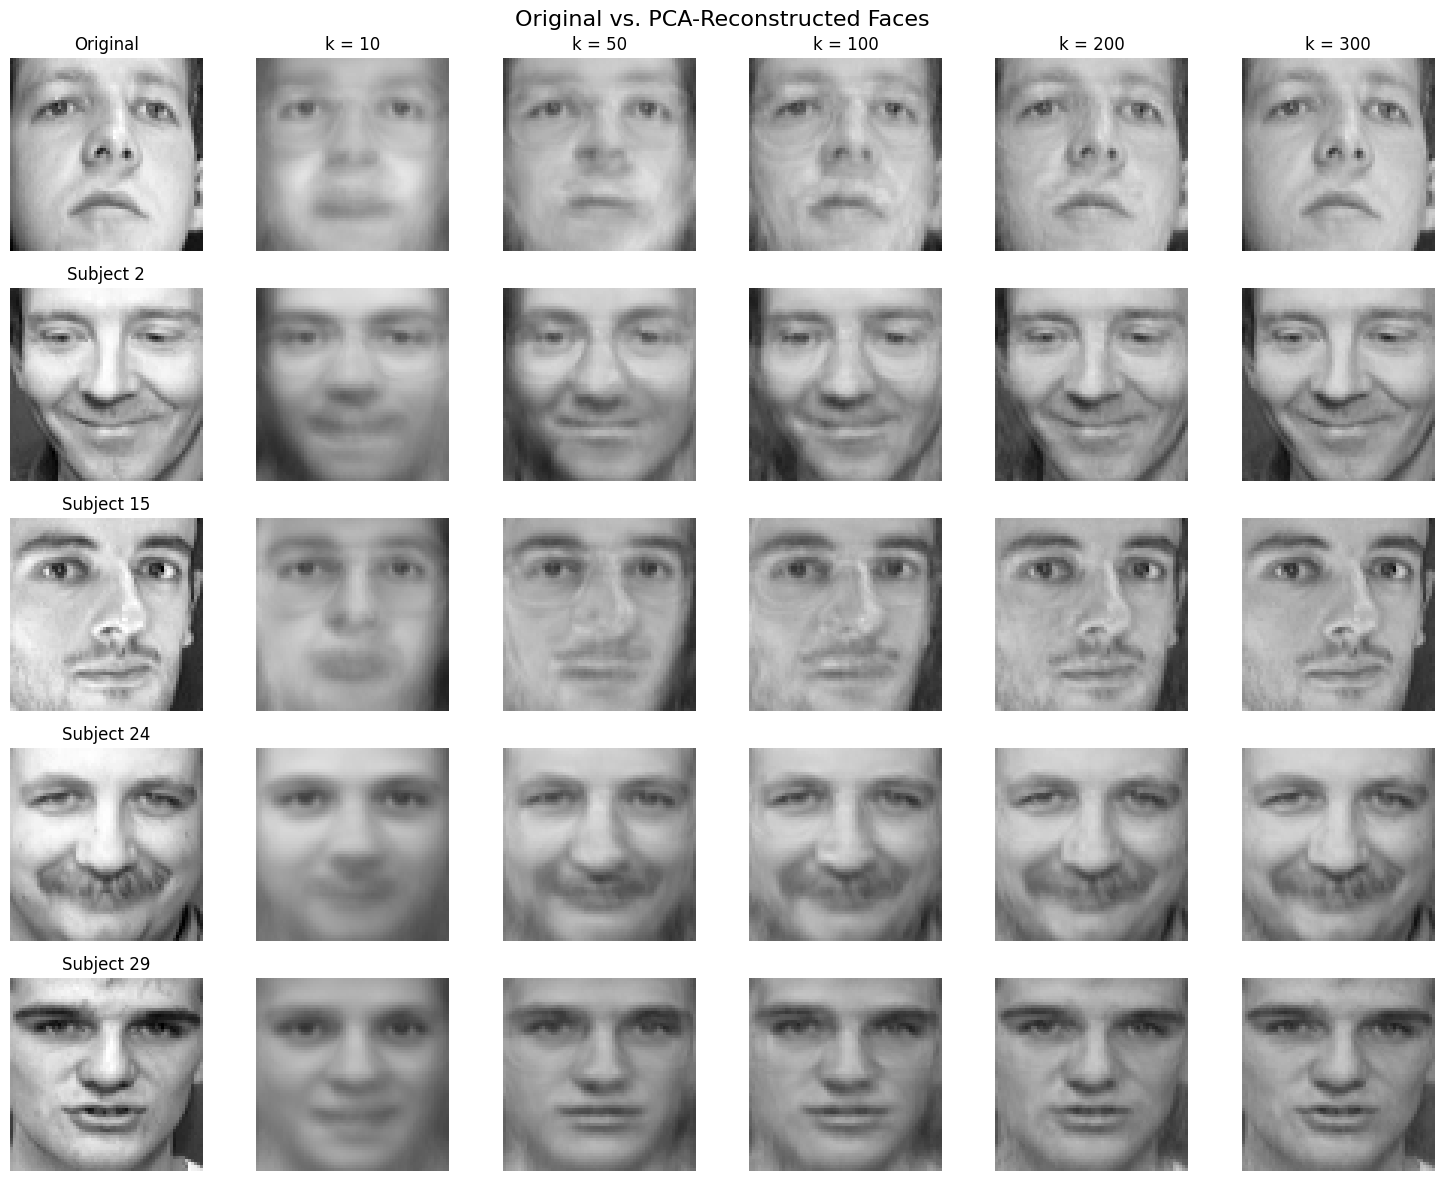

Mean Squared Error (MSE) by number of components:
k =  10: MSE = 0.005791
k =  50: MSE = 0.002500
k = 100: MSE = 0.001255
k = 200: MSE = 0.000398
k = 300: MSE = 0.000101


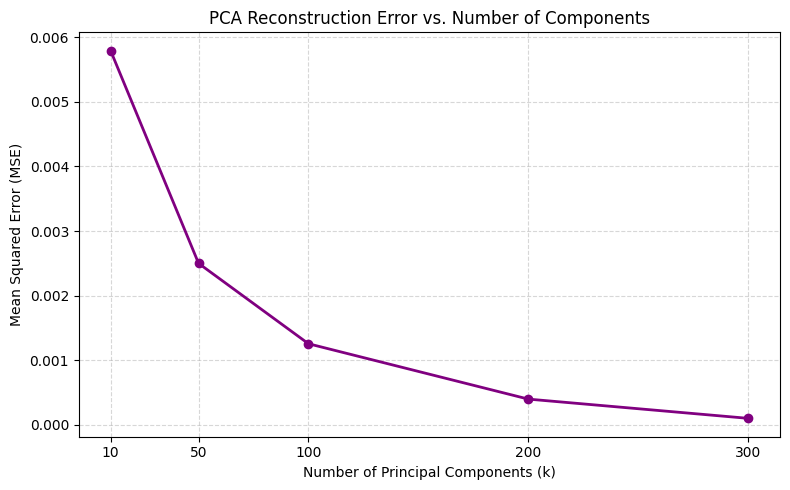

In [19]:
# Number of principal components to evaluate
k_values = [10, 50, 100, 200, 300]

# Selects 5 representative faces from different subjects
sample_indices = [8, 27, 156, 240, 299]
original_faces = X[sample_indices]

# Fits PCA using the maximum number of components needed
pca_reconstruction = PCA(n_components=max(k_values))
pca_reconstruction.fit(X)

# Stores reconstructed faces and MSE values
reconstructions = {}
mse_values = []

# Compresses and reconstructs the selected faces
for k in k_values:
  pca_k = PCA(n_components=k)
  pca_k.fit(X)
  compressed = pca_k.transform(original_faces)
  reconstructed = pca_k.inverse_transform(compressed)
  reconstructions[k] = reconstructed

  # Calculates MSE across all 5 faces and all pixels
  mse = mean_squared_error(original_faces.ravel(), reconstructed.ravel())
  mse_values.append(mse)

# Plots original images and reconstructions
fig, axes = plt.subplots(len(sample_indices), len(k_values) + 1, figsize=(15, 12))

# Original face
for row, idx in enumerate(sample_indices):
  axes[row, 0].imshow(faces.images[idx], cmap="gray")
  axes[row, 0].set_title("Original" if row == 0 else f"Subject {faces.target[idx]}")
  axes[row, 0].axis("off")

# Reconstructed faces for each k
  for col, k in enumerate(k_values, start=1):
    reconstructed_face = reconstructions[k][row].reshape(64, 64)
    axes[row, col].imshow(reconstructed_face, cmap="gray", vmin=0, vmax=1)

    if row == 0:
      axes[row, col].set_title(f"k = {k}")
    axes[row, col].axis("off")

plt.suptitle("Original vs. PCA-Reconstructed Faces", fontsize=16)
plt.tight_layout()
plt.show()

print("Mean Squared Error (MSE) by number of components:")
for k, mse in zip(k_values, mse_values):
  print(f"k = {k:3d}: MSE = {mse:.6f}")

# Plots MSE as a function of k
plt.figure(figsize=(8, 5))
plt.plot(k_values, mse_values, marker="o", linewidth=2, color="purple")
plt.xlabel("Number of Principal Components (k)")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("PCA Reconstruction Error vs. Number of Components")
plt.xticks(k_values)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

4) Visualization of "Eigenfaces"

Extract the principal components (eigenvectors) from your fitted PCA model. Reshape the first 15 principal components back into 64 x 64 grids and visualize them in a 3 x 5  plot grid ("Eigenfaces"). Annotate each plot with the percentage of total variance explained by that specific component.

Eigenfaces shape: (15, 4096)


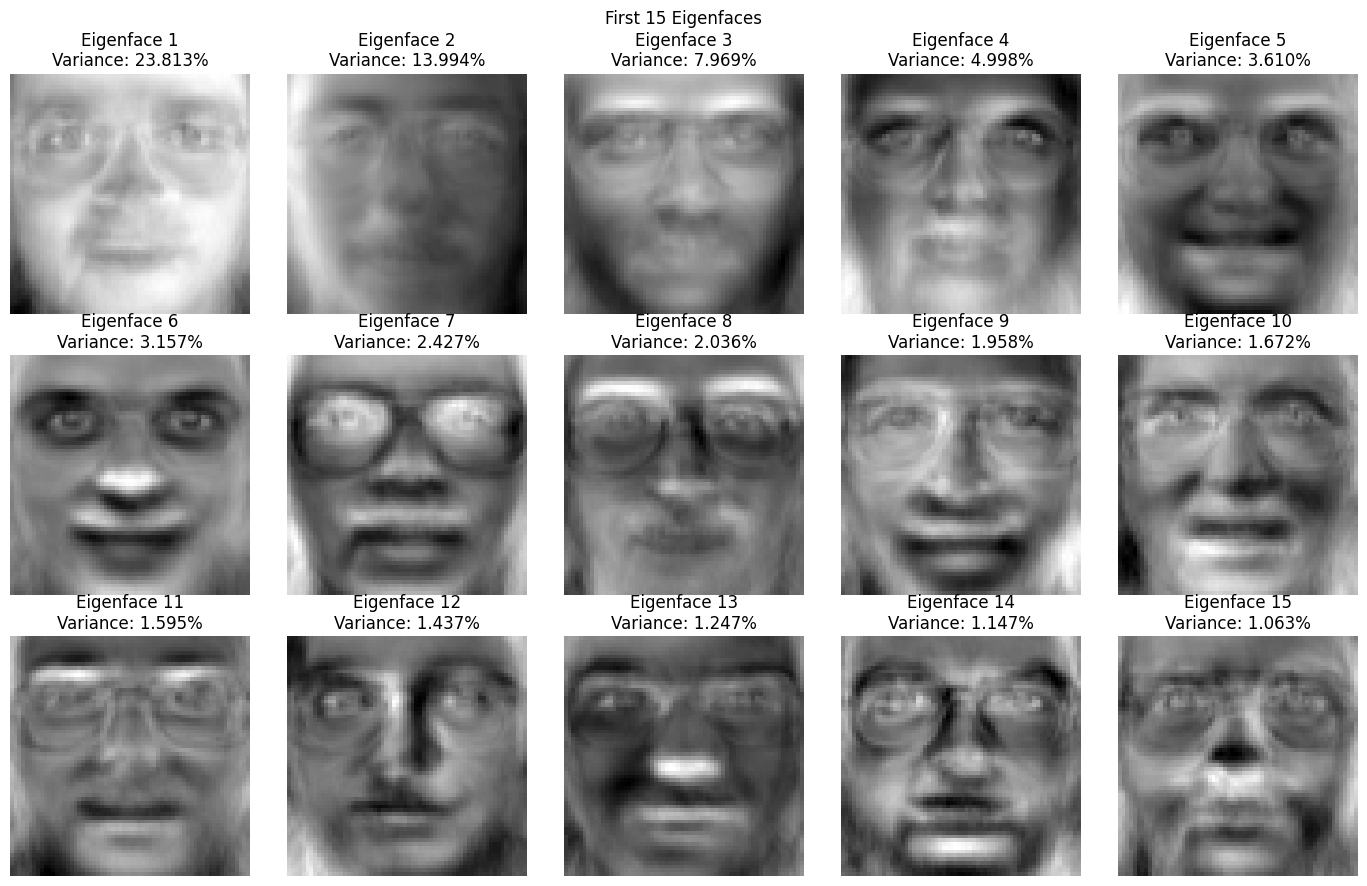

In [20]:
# Extracts the first 15 principal components
eigenfaces = pca.components_[:15]

# Individual explained variance for each component
eigenface_variance = pca.explained_variance_ratio_[:15] * 100
print("Eigenfaces shape:", eigenfaces.shape)

# Plots the first 15 eigenfaces in a 3 x 5 grid
fig, axes = plt.subplots(3, 5, figsize=(14, 9))
for i, ax in enumerate(axes.flat):
  eigenface = eigenfaces[i].reshape(64, 64)
  ax.imshow(eigenface, cmap="gray")
  ax.set_title(f"Eigenface {i + 1}\nVariance: {eigenface_variance[i]:.3f}%")
  ax.axis("off")

fig.suptitle("First 15 Eigenfaces", fontsize=12)
plt.tight_layout()
plt.show()

5) Classification Baseline — Raw vs. PCA-Reduced Features (Linear Model)

Perform a stratified train/test split (80/20). Train a LogisticRegression classifier on:

1. The raw 4,096-dimensional feature vectors.

2. The PCA-reduced feature vectors using the 95% variance threshold fitted strictly on the training set

Evaluate and print the test accuracy and training time for both, and visualize the performance comparison in a dual-axis bar plot (Accuracy vs. Training Time).

Training samples: 320
Testing samples: 80
PCA components required for 95% variance: 110
Training variance retained: 95.0294%
Reduced feature dimensions: 110

Logistic Regression comparison
Raw features: 96.2500% accuracy, 1.7888 seconds
PCA features: 96.2500% accuracy, 0.1894 seconds


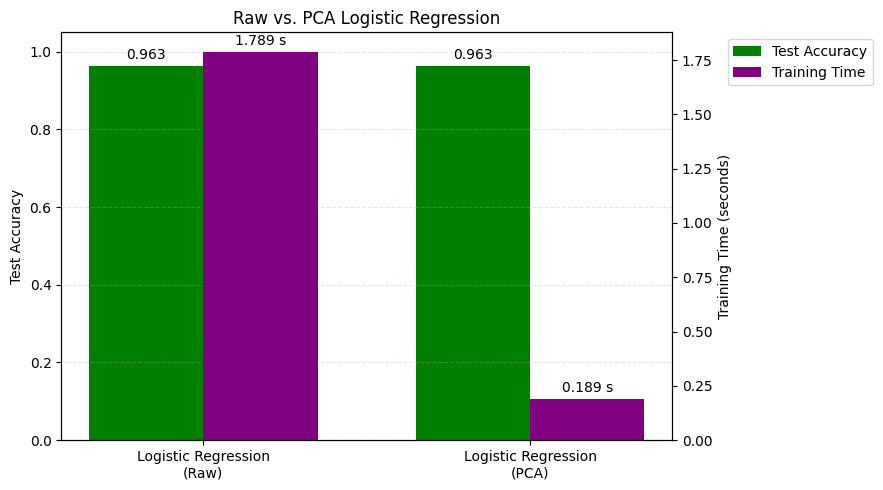

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, faces.target, test_size=0.20, stratify=faces.target, random_state=35)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Fits "PCA only" on the training data. Explains at least 95% of variance
pca = PCA(n_components=0.95, svd_solver="full")
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
print("PCA components required for 95% variance:", pca.n_components_)
print("Training variance retained:", f"{np.sum(pca.explained_variance_ratio_):.4%}")
print("Reduced feature dimensions:", X_train_pca.shape[1])
results = {}
predictions = {}

# Logistic Regression on raw features
raw_logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=35))
start = time.perf_counter()
raw_logreg.fit(X_train, y_train)
raw_time = time.perf_counter() - start
raw_pred = raw_logreg.predict(X_test)
raw_accuracy = accuracy_score(y_test, raw_pred)
results["Logistic Regression\n(Raw)"] = {"Accuracy": raw_accuracy, "Training Time": raw_time}
predictions["Logistic Regression (Raw)"] = raw_pred

# Logistic Regression on PCA-related variables
pca_logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=35))
start = time.perf_counter()
pca_logreg.fit(X_train_pca, y_train)
pca_logreg_time = time.perf_counter() - start
pca_logreg_pred = pca_logreg.predict(X_test_pca)
pca_logreg_accuracy = accuracy_score(y_test, pca_logreg_pred)
results["Logistic Regression\n(PCA)"] = {"Accuracy": pca_logreg_accuracy, "Training Time": pca_logreg_time}
predictions["Logistic Regression (PCA)"] = pca_logreg_pred
print("\nLogistic Regression comparison")
print(f"Raw features: {raw_accuracy:.4%} accuracy, {raw_time:.4f} seconds")
print(f"PCA features: {pca_logreg_accuracy:.4%} accuracy, "f"{pca_logreg_time:.4f} seconds")

# Dual-axis plot for the two Logistic Regression Models
baseline_names = ["Logistic Regression\n(Raw)", "Logistic Regression\n(PCA)"]
baseline_accuracy = [results[name]["Accuracy"] for name in baseline_names]
baseline_time = [results[name]["Training Time"] for name in baseline_names]
fig, ax1 = plt.subplots(figsize=(9, 5))
ax2 = ax1.twinx()
positions = np.arange(len(baseline_names))
width = 0.35
bars1 = ax1.bar(positions - width / 2, baseline_accuracy, width, color="green", label="Test Accuracy")
bars2 = ax2.bar(positions + width / 2, baseline_time, width, color="purple", label="Training Time")
ax1.set_ylabel("Test Accuracy")
ax2.set_ylabel("Training Time (seconds)")
ax1.set_xticks(positions)
ax1.set_xticklabels(baseline_names)
ax1.set_ylim(0, 1.05)
ax1.set_title("Raw vs. PCA Logistic Regression")
ax1.bar_label(bars1, fmt="%.3f", padding=3)
ax2.bar_label(bars2, fmt="%.3f s", padding=3)
handles = [bars1, bars2]
labels = [h.get_label() for h in handles]
ax1.legend(handles, labels, loc="upper left", bbox_to_anchor=(1.08, 1), frameon=True,)
ax1.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

6) Non-Linear Classification (Kernel SVM)

Train a SVC with an RBF kernel on the PCA-reduced features (95% variance). Record its training time and test accuracy...

In [22]:
rbf_svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=35))
start = time.perf_counter()
rbf_svm.fit(X_train_pca, y_train)
rbf_time = time.perf_counter() - start
rbf_pred = rbf_svm.predict(X_test_pca)
rbf_accuracy = accuracy_score(y_test, rbf_pred)
results["RBF SVM\n(PCA)"] = {"Accuracy": rbf_accuracy, "Training Time": rbf_time}
predictions["RBF SVM (PCA)"] = rbf_pred
print("\nRBF SVM")
print(f"Test accuracy: {rbf_accuracy:.4%}")
print(f"Training time: {rbf_time:.4f} seconds")


RBF SVM
Test accuracy: 96.2500%
Training time: 0.3412 seconds


7) Ensemble Classification on PCA Features

Construct a VotingClassifier (soft voting) combining a Polynomial Kernel SVM (degree=2), an RBF Kernel SVM, and a RandomForestClassifier (n_estimators=100). Train the ensemble on the PCA-reduced features, record training time and accuracy...

In [23]:
poly_svm = SVC(kernel="poly", degree=2, probability=True, random_state=35)
rbf_svm_ensemble = SVC(kernel="rbf", probability=True, random_state=35)
random_forest = RandomForestClassifier(n_estimators=100, random_state=35, n_jobs=-1)
voting = VotingClassifier(estimators=[("poly_svm", poly_svm), ("rbf_svm", rbf_svm_ensemble), ("random_forest", random_forest)], voting="soft", n_jobs=-1)
ensemble = make_pipeline(StandardScaler(), voting)
start = time.perf_counter()
ensemble.fit(X_train_pca, y_train)
ensemble_time = time.perf_counter() - start
ensemble_pred = ensemble.predict(X_test_pca)
ensemble_accuracy = accuracy_score(y_test, ensemble_pred)
results["Soft Voting Ensemble\n(PCA)"] = {"Accuracy": ensemble_accuracy, "Training Time": ensemble_time}
predictions["Soft Voting Ensemble (PCA)"] = ensemble_pred
print("\nSoft Voting Ensemble")
print(f"Test accuracy: {ensemble_accuracy:.4%}")
print(f"Training time: {ensemble_time:.4f} seconds")


Soft Voting Ensemble
Test accuracy: 96.2500%
Training time: 5.7224 seconds


6) ... and plot a confusion matrix or classification summary comparing its predictions against the linear baseline.
7) ... and compare its performance against the single linear and non-linear models.

In [24]:
summary = []
for model_name, y_pred in predictions.items():
  summary.append({"Model": model_name, "Accuracy": accuracy_score(y_test, y_pred), "Weighted Precision": precision_score( y_test, y_pred, average="weighted", zero_division=0),
    "Weighted Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
    "Weighted F1": f1_score(y_test, y_pred, average="weighted", zero_division=0)})
summary_df = pd.DataFrame(summary)
print("\nCLASSIFICATION PERFORMANCE SUMMARY")
print(summary_df.round(4).to_string(index=False))
print("\nRBF SVM CLASSIFICATION REPORT")
print(classification_report(y_test, rbf_pred, zero_division=0))


CLASSIFICATION PERFORMANCE SUMMARY
                     Model  Accuracy  Weighted Precision  Weighted Recall  Weighted F1
 Logistic Regression (Raw)    0.9625              0.9750           0.9625       0.9600
 Logistic Regression (PCA)    0.9625              0.9708           0.9625       0.9608
             RBF SVM (PCA)    0.9625              0.9750           0.9625       0.9600
Soft Voting Ensemble (PCA)    0.9625              0.9750           0.9625       0.9600

RBF SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       1.00      1.00      1.00         2
           2       1.00      0.50      0.67         2
           3       1.00      1.00      1.00         2
           4       1.00      0.50      0.67         2
           5       1.00      1.00      1.00         2
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         2
           

8) Comprehensive Comparative Evaluation

Create a single summary bar plot comparing Accuracy (primary y-axis) and Training Time in seconds (secondary y-axis) across all four model configurations:

1. Logistic Regression (Raw Features)
2. Logistic Regression (PCA-Reduced)
3. Support Vector Classifier with RBF Kernel (PCA-Reduced)
4. Soft Voting Ensemble (PCA-Reduced)

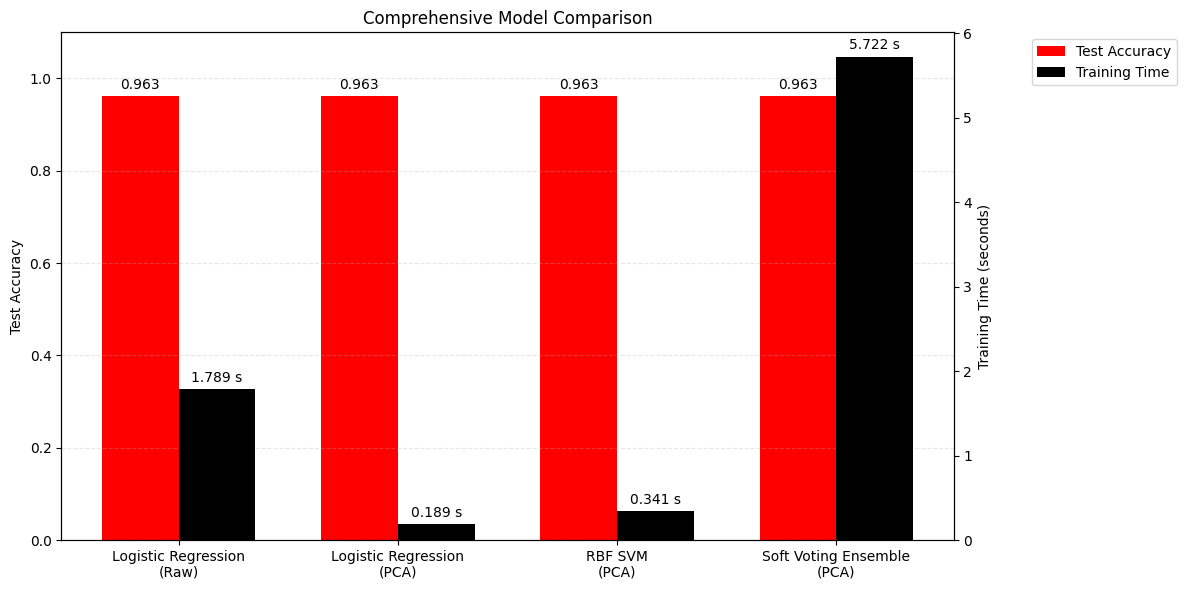

In [26]:
model_names = list(results.keys())
accuracies = [results[name]["Accuracy"] for name in model_names]
training_times = [results[name]["Training Time"] for name in model_names]
fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()
positions = np.arange(len(model_names))
width = 0.35
bars1 = ax1.bar(positions - width / 2, accuracies, width, color="red", label="Test Accuracy")
bars2 = ax2.bar(positions + width / 2, training_times, width, color="black", label="Training Time")
ax1.set_ylabel("Test Accuracy")
ax2.set_ylabel("Training Time (seconds)")
ax1.set_ylim(0, 1.10)
ax1.set_xticks(positions)
ax1.set_xticklabels(model_names)
ax1.set_title("Comprehensive Model Comparison")
ax1.bar_label(bars1, fmt="%.3f", padding=3)
ax2.bar_label(bars2, fmt="%.3f s", padding=3)
handles = [bars1, bars2]
labels = [h.get_label() for h in handles]
ax1.legend(handles, labels, loc="upper left", bbox_to_anchor=(1.08, 1), frameon=True,)
ax1.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()